# Eksploracyjna Analiza Danych dla nieprzetworzonych danych

## Importowanie bibliotek

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os 
from datetime import datetime, timedelta

## Ładowanie Danych

In [34]:
DATA_ARRAY = {}
directory = '../data/raw'
for file in os.listdir(directory):
    file_path = os.path.join(directory,file)
    finish_date = datetime.strptime(file.removesuffix('.csv'), '%d-%m-%Y')
    start_date = finish_date - timedelta(days=5)
    df = pd.read_csv(file_path)
    DATA_ARRAY[start_date.strftime('%d-%m-%Y') + ' do ' + finish_date.strftime('%d-%m-%Y') ] = df

compacted_data = pd.concat(DATA_ARRAY)




## Sprawdzenie tabel z każdego okresu akwizycji danych

### Wymiary tabel i podstawowe dane

In [35]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}-------------\n')
    print('Ilość kolumn:', df.shape[1])
    print('Ilość wierszy:',df.shape[0])
    print('Typy danych kolumn:')
    print(df.dtypes,'\n')
    print('Ilość wartości Nan:')
    print(df.isnull().sum())
    


-------------12-10-2026 do 17-10-2026-------------

Ilość kolumn: 8
Ilość wierszy: 376
Typy danych kolumn:
date            object
link            object
title           object
content         object
company_name    object
ticker          object
category        object
source          object
dtype: object 

Ilość wartości Nan:
date              0
link              8
title             8
content           8
company_name    193
ticker          193
category          0
source            0
dtype: int64
-------------18-10-2026 do 23-10-2026-------------

Ilość kolumn: 8
Ilość wierszy: 608
Typy danych kolumn:
date            object
link            object
title           object
content         object
company_name    object
ticker          object
category        object
source          object
dtype: object 

Ilość wartości Nan:
date              0
link              4
title             4
content           4
company_name    304
ticker          304
category          0
source            0
dtype: int64


## Duplikaty

### Duplikaty w kolumnie z linkami

In [36]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}-------------\n')
    column_names=list(df)
    print(column_names)
    for name in column_names:
        print(name + ':', df[name].duplicated().sum())
    dups_link = df.pivot_table(index = ['link'], aggfunc ='size')
    print(dups_link[dups_link > 1])




-------------12-10-2026 do 17-10-2026-------------

['date', 'link', 'title', 'content', 'company_name', 'ticker', 'category', 'source']
date: 56
link: 30
title: 47
content: 56
company_name: 363
ticker: 363
category: 368
source: 373
link
https://biznes.pap.pl/wiadomosci/firmy/bgk-na-przetargu-zamiany-sprzedal-obligacje-fpc-za-156-mld-zl-odkupil-za-16-mld-zl       2
https://biznes.pap.pl/wiadomosci/firmy/cena-obligacji-fpc0427-na-czwartkowym-przetargu-zamiany-bgk-wynosi-98890-zl              2
https://biznes.pap.pl/wiadomosci/firmy/pzu-sa-262026-powolanie-czlonka-rady-nadzorczej-pzu-sa                                   2
https://biznes.pap.pl/wiadomosci/firmy/w-czechach-blizej-do-opodatkowania-rafinerii-orlenu-projekt-przeszedl-pierwsze           2
https://biznes.pap.pl/wiadomosci/gospodarka/dzien-na-fxfi-jest-przestrzen-do-dalszego-oslabienia-usd-co-moze-wspierac-pln       2
https://biznes.pap.pl/wiadomosci/gospodarka/dzien-na-fxfi-notowania-eurpln-powinny-utrzymac-sie-w-konsolidacji-4

Niektóre linki się pojawiają więcej niż raz, ponieważ przy zbieraniu danych scrapujemy róże tagi i te wiadomości mogą się pojawić kilkukrotnie, dlatego trzeba je wyfiltrować

Fakt, że jest dużo duplikatów dla nazwy firmy, i ticker świadczy tylko o wiele pustych wartościach, które LLM będzie musiał dopasować.

### Duplikaty po usunięciu duplikatów bazując na kolumnie link

In [37]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}-------------\n')
    df.drop_duplicates(inplace = True, subset=['link'])
    dups_content = df.pivot_table(index = ['content'], aggfunc ='size')
    print('ilość duplikatów content:',df['content'].duplicated().sum())
    print('ilość duplikatów title:',df['title'].duplicated().sum())
    




-------------12-10-2026 do 17-10-2026-------------

ilość duplikatów content: 26
ilość duplikatów title: 17
-------------18-10-2026 do 23-10-2026-------------

ilość duplikatów content: 46
ilość duplikatów title: 39


In [38]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}-------------\n')
    dups_title = df.pivot_table(index = ['title'], aggfunc ='size')
    dups_title_check = df[df['title'].isin(dups_title[dups_title > 1].index)]    
    pd.options.display.max_colwidth = None
    print(dups_title_check[['link','title','content']])
    

-------------12-10-2026 do 17-10-2026-------------

                                                                                                                                   link  \
0                                              https://biznes.pap.pl/wiadomosci/firmy/udzial-erste-bp-w-erste-tfi-spadl-do-ok-4999-proc   
1                  https://biznes.pap.pl/wiadomosci/firmy/erste-bank-polska-sa-362026-informacja-o-zamknieciu-transakcji-zbycia-przez-0   
2              https://biznes.pap.pl/wiadomosci/firmy/erste-bank-polska-sa-362026-informacja-o-zamknieciu-transakcji-zbycia-przez-erste   
7                      https://biznes.pap.pl/wiadomosci/firmy/bp-ocenia-polski-rynek-paliw-jako-bardzo-atrakcyjny-chce-utrzymac-pozycje   
10                                        https://biznes.pap.pl/wiadomosci/gospodarka/pko-bp-chce-osiagnac-30-proc-udzialow-w-rynku-oki   
15                      https://biznes.pap.pl/wiadomosci/gry-i-technologie/pge-i-nask-chca-wspolnie-inwestowac-w-c

### Pojedeńczy przykład powtórzonego title

Sprawdzimy wiersz z title = Udział Erste BP w Erste TFI spadł do ok. 49,99 proc.   

In [39]:
print(compacted_data.loc[compacted_data['title'] == 'Udział Erste BP w Erste TFI spadł do ok. 49,99 proc.'])


                                             date  \
12-10-2026 do 17-10-2026 0    2026-10-15 10:59:00   
                         262  2026-10-15 11:00:00   

                                                                                                                          link  \
12-10-2026 do 17-10-2026 0            https://biznes.pap.pl/wiadomosci/firmy/udzial-erste-bp-w-erste-tfi-spadl-do-ok-4999-proc   
                         262  https://www.bankier.pl/wiadomosc/Udzial-Erste-BP-w-Erste-TFI-spadl-do-ok-49-99-proc-9213067.html   

                                                                             title  \
12-10-2026 do 17-10-2026 0    Udział Erste BP w Erste TFI spadł do ok. 49,99 proc.   
                         262  Udział Erste BP w Erste TFI spadł do ok. 49,99 proc.   

                                                                                                                                                                                              

Czas lekko się różni oraz różni się portal, w którym pobrano wiadomości. Dzieję się to, ponieważ bankier.pl pobiera wiadomości z Pap biznes, dlatego najpierw pojawia się najpierw wiadomość na portlau PAP Biznes, a minutę później na Bankier.pl. Takich przypadków jest więcej, dlatego trzeba wyfiltrować wiadomości po kolumnie content oraz title.

### Czyszczenie duplikatów w kolumnach content i title

In [40]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}-------------\n')
    print("-----------USUWANIE DUPLIKATÓW Z KOLUMNY CONTENT-----------")
    df.drop_duplicates(inplace = True, subset=['content'])
    print('ilość duplikatów content:',df['content'].duplicated().sum())
    print('ilość duplikatów title:',df['title'].duplicated().sum())
    print("-----------USUWANIE DUPLIKATÓW Z KOLUMNY TITLE-----------")
    df.drop_duplicates(inplace = True, subset=['title'])
    print('ilość duplikatów content:',df['content'].duplicated().sum())
    print('ilość duplikatów title:',df['title'].duplicated().sum())

-------------12-10-2026 do 17-10-2026-------------

-----------USUWANIE DUPLIKATÓW Z KOLUMNY CONTENT-----------
ilość duplikatów content: 0
ilość duplikatów title: 7
-----------USUWANIE DUPLIKATÓW Z KOLUMNY TITLE-----------
ilość duplikatów content: 0
ilość duplikatów title: 0
-------------18-10-2026 do 23-10-2026-------------

-----------USUWANIE DUPLIKATÓW Z KOLUMNY CONTENT-----------
ilość duplikatów content: 0
ilość duplikatów title: 21
-----------USUWANIE DUPLIKATÓW Z KOLUMNY TITLE-----------
ilość duplikatów content: 0
ilość duplikatów title: 0


### Podsumowanie ilości po usuwaniu duplikatów

In [41]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}-------------\n')
    column_names=list(df)
    print("Ilość wszystkich wierszy:", df.shape[0])
    for name in column_names:
        print(name + ':', df[name].duplicated().sum())

compacted_data = pd.concat(DATA_ARRAY)

-------------12-10-2026 do 17-10-2026-------------

Ilość wszystkich wierszy: 313
date: 28
link: 0
title: 0
content: 0
company_name: 301
ticker: 301
category: 305
source: 310
-------------18-10-2026 do 23-10-2026-------------

Ilość wszystkich wierszy: 502
date: 49
link: 0
title: 0
content: 0
company_name: 486
ticker: 486
category: 494
source: 499


## Wizualizacja danych podzielonych na kategorie i źródła 

### Wymiary danych dla poszczególnych źródeł

In [42]:
print('-------Skumulowane dane-------\n')
print("Źródła:", compacted_data['source'].value_counts())
print()

print('Kategorie:', compacted_data['category'].value_counts())

-------Skumulowane dane-------

Źródła: source
pap        408
bankier    338
wykop       69
Name: count, dtype: int64

Kategorie: category
bankier        338
economy        161
market         158
profiles        89
technologia     31
finanse         23
gospodarka      13
inwestycje       2
Name: count, dtype: int64


Kategorie economy, market i profiles należą do pap, technologia, finanse, gospodarka, inwestycje należą do wykop, a bankier jak sama nazwa wskazuję do bankier

## Wizualizacja danych na wykresie

### Źródła

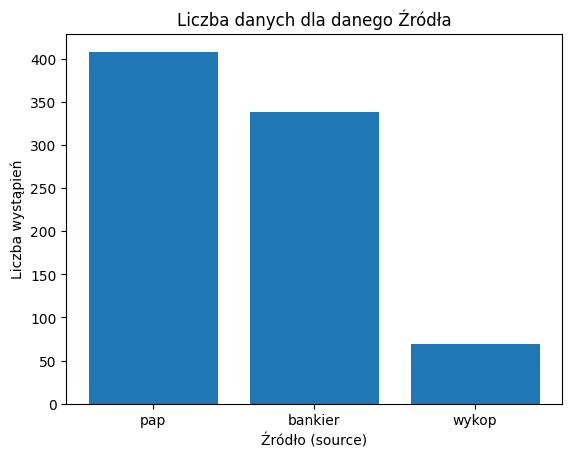

In [43]:
counts = compacted_data['source'].value_counts()

plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Źródło (source)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danego Źródła')
plt.show()

### Kategorie Pap

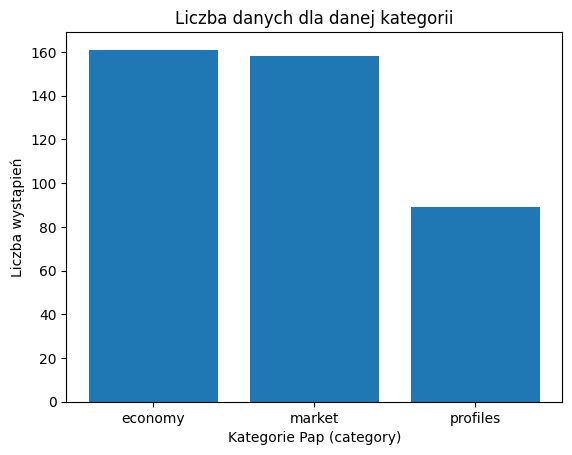

In [44]:
counts = compacted_data[compacted_data['source'] == 'pap']['category'].value_counts()

plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Pap (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()

### Kategoria Bankier

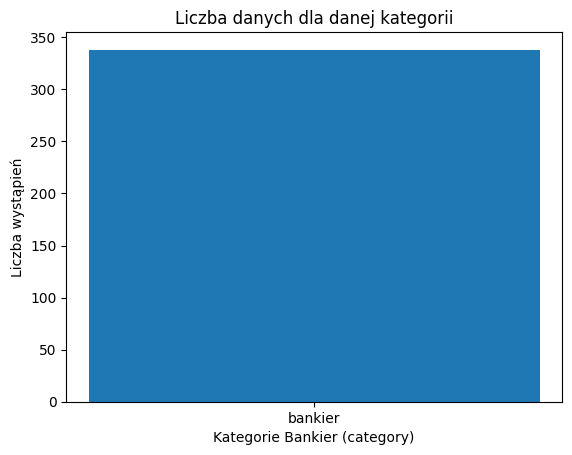

In [45]:
counts = compacted_data[compacted_data['source'] == 'bankier']['category'].value_counts()

plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Bankier (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()

Kategorie Wykop

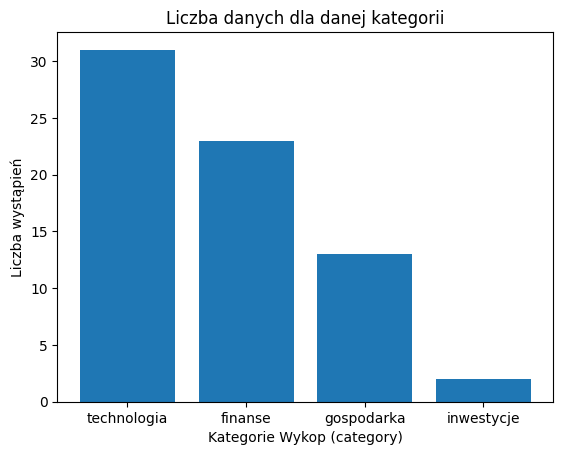

In [46]:
counts = compacted_data[compacted_data['source'] == 'wykop']['category'].value_counts()

plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Wykop (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()